# GENIE BPC PANC v1.0-public — question P1

Source: Jacob's *CBIO thoughts* deck, slide 24. Data: AACR Project GENIE BPC PANC v1.0-public (Synapse).

Conventions as in `README.md`: index date = diagnosis of the index pancreatic cancer, OS in months; *X mut* = non-synonymous mutation;
`amp` / `homdel` / `fus` separate; patients compared for a gene only if their panel covers it; KM / log-rank as cBioPortal, Cox HR
left-truncated at the sequencing report (*HR (LT)*). Pancreatic cancer is sequenced late and dies fast, so left truncation matters more here than anywhere else in the deck.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "bpc_panc"
F = []

b = cb.BPC("PANC")
pd.Series(b.summary())

cohort                            PANC
patients                          1109
index_cancers                     1110
patients_with_2+_index_cancers       1
samples                           1128
samples_used                      1109
regimens                          2959
mutations_nonsyn                  6745
cna_profiled_samples               963
sv_rows                            384
dtype: object

## Data pin

In [2]:
log = pd.read_csv(cb.DATA / "genie" / "download_log.csv")
print("release_version:", b.index.release_version.unique())
log[log.cohort == "PANC"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]]

release_version: ['1.0-public']


,category,filename,synapse_id,version,md5
34,docs,GENIE BPC PANC 1.0-public Analytic Data Guide.pdf,syn72666511,1,7478dcf187495d7afeddcf6b6fe597d9
35,docs,GENIE BPC PANC v1.0-public Variable Synopsis.xlsx,syn72666512,1,b8c75ba36fb17c9adc68502c3b722849
36,docs,GENIE BPC PANC v1.0-public Release Notes.pdf,syn72666513,1,3deb4fa77aa8a37844af11c66a3c72ec
37,analytic,patient_level_dataset.csv,syn72666502,1,d2cfea3f3d7de29da99f407d73034539
38,analytic,cancer_level_dataset_index.csv,syn72666500,1,cefd22b0a76ef5ab4bcf8fe12d0be158
39,analytic,cancer_level_dataset_non_index.csv,syn72666507,1,c2873d81f33c5242b5a6007ad1779e9a
40,analytic,cancer_panel_test_level_dataset.csv,syn72666499,1,242e706962932668329b15a774d78261
41,analytic,regimen_cancer_level_dataset.csv,syn72666503,1,fe9b7253113aa42953de943ac8e13f00
42,analytic,imaging_level_dataset.csv,syn72666505,1,9e8081f8e1ad0fb8cf3bae4c92a90af9
43,analytic,med_onc_note_level_dataset.csv,syn72666508,1,5b3b0223d46324e9543b1922cadd2593


## Cohort and alteration matrix

,step,n,dropped
0,Patients in release,1109,0
1,Index pancreatic cancer (first index cancer pe...,1109,0
2,With a sequenced sample of the index cancer,1109,0
3,With OS from diagnosis,1109,0


1 patients had two index cancers (first used); 0 samples with unknown panel; 63 patients with sequencing report after last follow-up (dropped from left-truncated models only).
Deaths: 879 / 1109.  Median OS from dx: 22.1 months; median months from diagnosis to sequencing report: 4.4.


stage_dx
Stage IV           497
Stage II           450
Stage III          108
Stage I             46
Stage I-III NOS      8
Name: stage_dx, dtype: int64

,gene,kind,n_altered,n_tested,pct
0,KRAS,mut,952,1109,85.8
1,TP53,mut,774,1109,69.8
2,SMAD4,mut,230,1109,20.7
3,CDKN2A,mut,229,1109,20.6
4,CDKN2A,homdel,138,946,14.6
5,CDKN2B,homdel,130,946,13.7
6,ARID1A,mut,82,1057,7.8
7,KMT2D,mut,76,1054,7.2
8,ATM,mut,64,1109,5.8
9,BRCA2,mut,57,1057,5.4


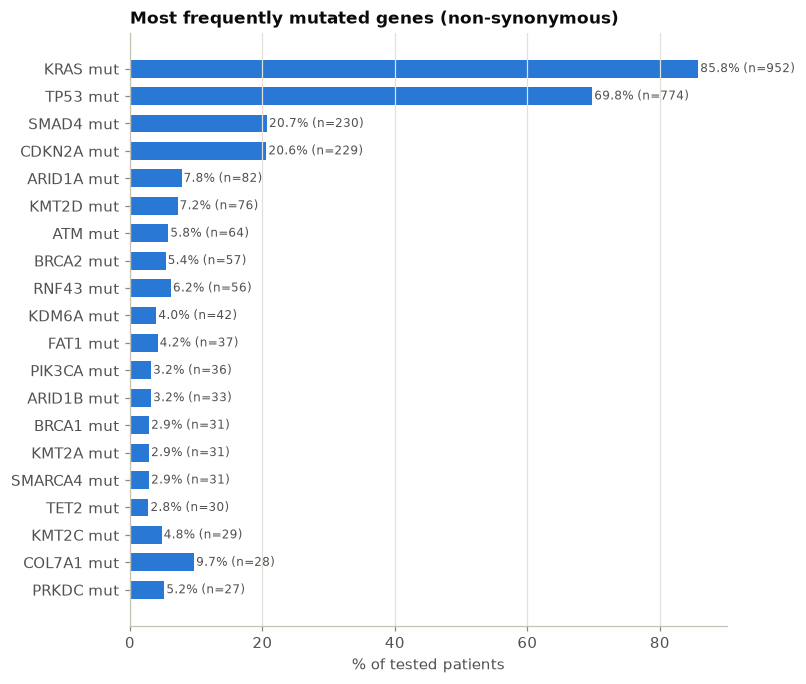

In [3]:
S = b.survival_dx()
A = b.alterations()
display(cb.consort([
    ("Patients in release", len(b.patients)),
    ("Index pancreatic cancer (first index cancer per patient)", len(b.index)),
    ("With a sequenced sample of the index cancer", int(S.entry.notna().sum())),
    ("With OS from diagnosis", int(S.time.notna().sum())),
]))
print(f"{b.n_multi_index} patients had two index cancers (first used); {A.n_unknown_panel} samples with unknown panel; "
      f"{int((S.entry >= S.time).sum())} patients with sequencing report after last follow-up (dropped from left-truncated models only).")
print(f"Deaths: {int(S.event.sum())} / {len(S)}.  Median OS from dx: {cb.km_table(S.assign(g='all'), 'g').median_months[0]} months; "
      f"median months from diagnosis to sequencing report: {S.entry.median():.1f}.")
display(S.stage_dx.value_counts().rename("stage_dx"))
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"))
ax = cb.bar_freq(freq[freq.kind == "mut"], top=20, title="Most frequently mutated genes (non-synonymous)")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")
freq.head(15)

## P1 — How is OS of KRAS-mutant patients further differentiated by co-mutations? Which co-mutations associate with worse outcome?
Within KRAS-mutant patients: every co-alteration (mutation, amplification, deep deletion) with ≥ 10 carriers and non-carriers; log-rank,
left-truncated Cox HR, BH FDR. CDKN2A / CDKN2B / MTAP deep deletions are of special interest and are shown individually, as is the
KRAS-wild-type group for reference.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,KRAS wt,157,116,32.2,0.855,0.619,0.232,2.03e-06,NaN,NaN,NaN,NaN
1,KRAS mut,952,763,20.6,0.71,0.434,0.117,2.03e-06,1.42,1.16,1.74,0.000794


,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,CDKN2A homdel,CDKN2A,homdel,128,714,108,557,14.9,21.3,3.63e-05,1.47,1.19,1.82,0.000347,794,0.0021
1,CDKN2B homdel,CDKN2B,homdel,120,722,102,563,15.4,21,4.92e-05,1.53,1.24,1.9,0.000107,794,0.0021
2,SMAD4 homdel,SMAD4,homdel,43,799,35,630,10.7,20.4,6.65e-05,1.66,1.16,2.36,0.00522,794,0.00213
3,NTRK3 mut,NTRK3,mut,15,909,14,723,12,20.6,0.000917,2.32,1.36,3.96,0.00191,873,0.0235
4,FLCN mut,FLCN,mut,10,908,10,722,11.1,20.5,0.00426,2.23,1.19,4.17,0.012,867,0.0908
5,CDKN2A mut,CDKN2A,mut,220,732,189,574,16.9,22.1,0.00583,1.29,1.09,1.52,0.0033,900,0.0929
6,TP53 mut,TP53,mut,737,215,595,168,19.1,25.2,0.00687,1.26,1.06,1.5,0.00908,900,0.0929
7,AKT2 amp,AKT2,amp,33,809,32,633,15.5,20.1,0.00699,1.53,1.06,2.21,0.0236,794,0.0929
8,CDK12 amp,CDK12,amp,11,831,10,655,14.8,19.9,0.00726,1.89,1.01,3.53,0.0467,794,0.0929
9,SMARCA4 mut,SMARCA4,mut,30,894,28,709,10.4,20.8,0.00971,2.38,1.61,3.5,1.2e-05,873,0.107


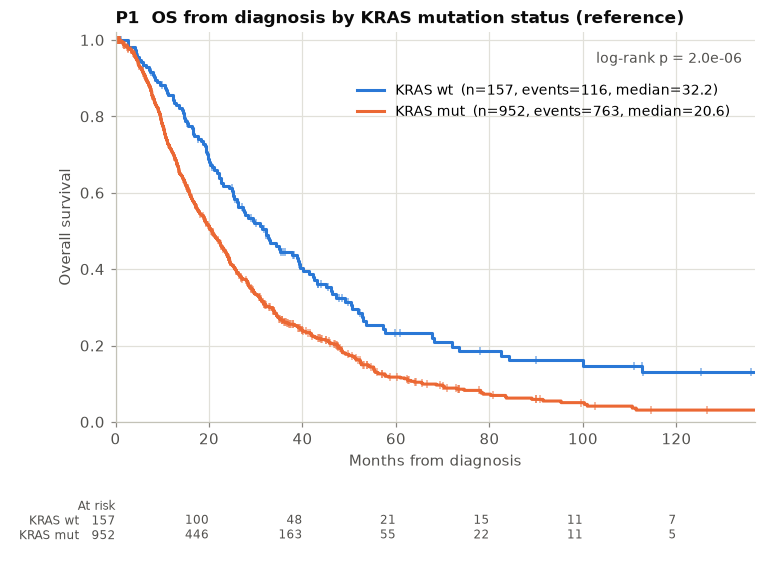

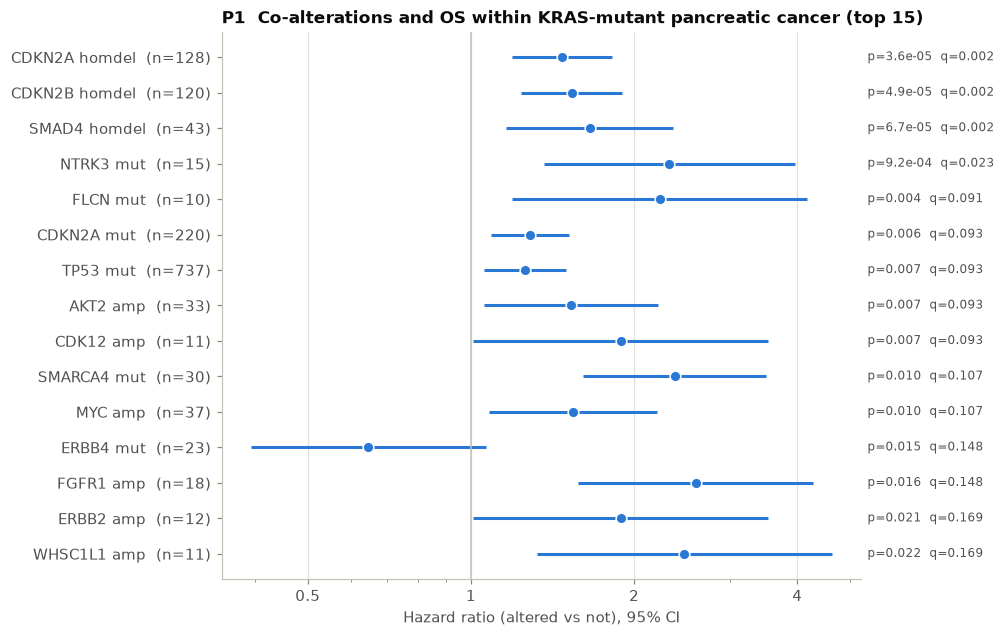

In [4]:
kras = A.status("KRAS")
kras_ids = kras.index[kras]
d, t0 = cb.compare(S, kras, labels=("KRAS wt", "KRAS mut"), entry="entry")
ax, _ = cb.km_plot(d, "group", order=["KRAS wt", "KRAS mut"], title="P1  OS from diagnosis by KRAS mutation status (reference)", xlabel="Months from diagnosis")
cb.save(DS, "P1", table=t0, fig=ax.figure, slug="kras_vs_wt")
display(t0)
scr = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel"), min_n=10, entry="entry", patients=kras_ids)
scr = scr[scr.gene != "KRAS"].reset_index(drop=True)
ax = cb.forest_plot(scr, top=15, title="P1  Co-alterations and OS within KRAS-mutant pancreatic cancer (top 15)")
cb.save(DS, "P1", table=scr, fig=ax.figure, slug="comutation_screen_in_kras")
display(scr.head(15))

n  events  median_months  surv_1y  surv_2y  surv_5y  p_logrank    HR  HR_lo  HR_hi    p_cox
feature       group                                                                                                               
CDKN2A homdel CDKN2A homdel absent   714     557           21.3    0.717     0.45    0.134   3.63e-05   NaN    NaN    NaN      NaN
              CDKN2A homdel present  128     108           14.9    0.573    0.247    0.064   3.63e-05  1.47   1.19   1.82 0.000347
CDKN2B homdel CDKN2B homdel absent   722     563             21    0.712    0.445    0.135   4.92e-05   NaN    NaN    NaN      NaN
              CDKN2B homdel present  120     102           15.4    0.596    0.265    0.054   4.92e-05  1.53   1.24    1.9 0.000107
MTAP homdel   MTAP homdel absent     815     640           19.9    0.698    0.424    0.127     0.0327   NaN    NaN    NaN      NaN
              MTAP homdel present     27      25           14.4     0.63    0.296        0     0.0327   1.4  0.924   2.13    0.112
CDKN2A mut    CDKN2A mut absent      732     574           22.1    0.728    0.461    0.124    0.00583   NaN    NaN    NaN      NaN
              CDKN2A mut present     220     189           16.9     0.65    0.346    0.093    0.00583  1.29   1.09   1.52   0.0033
TP53 mut      TP53 mut absent        215     168           25.2    0.796    0.521    0.142    0.00687   NaN    NaN    NaN      NaN
              TP53 mut present       737     595           19.1    0.684    0.408     0.11    0.00687  1.26   1.06    1.5  0.00908
SMAD4 mut     SMAD4 mut absent       736     585           20.1    0.698    0.436    0.122      0.899   NaN    NaN    NaN      NaN
              SMAD4 mut present      216     178           21.5    0.747    0.428    0.102      0.899 0.971  0.819   1.15    0.739
SMAD4 homdel  SMAD4 homdel absent    799     630           20.4    0.711    0.432    0.126   6.65e-05   NaN    NaN    NaN      NaN
              SMAD4 homdel present    43      35           10.7    0.389    0.181     0.13   6.65e-05  1.66   1.16   2.36  0.00522

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,not co-deleted,816,641,19.9,0.698,0.424,0.127,0.0455,NaN,NaN,NaN,NaN
1,CDKN2A + MTAP co-deleted,26,24,14.4,0.615,0.308,0,0.0455,1.04,0.679,1.61,0.842


[P1] signal: KRAS-mut n=952. FDR<0.1 co-alterations: CDKN2A homdel (n=128) HR 1.47 q=0.0021, CDKN2B homdel (n=120) HR 1.53 q=0.0021, SMAD4 homdel (n=43) HR 1.66 q=0.0021, NTRK3 mut (n=15) HR 2.32 q=0.023, FLCN mut (n=10) HR 2.23 q=0.091, CDKN2A mut (n=220) HR 1.29 q=0.093, TP53 mut (n=737) HR 1.26 q=0.093, AKT2 amp (n=33) HR 1.53 q=0.093, CDK12 amp (n=11) HR 1.89 q=0.093. CDKN2A homdel n=128.0: median 14.9 vs 21.3 mo, HR (LT) 1.47 (p=3.5e-04); MTAP homdel n=27.0: HR 1.40 (p=0.112); co-deletion adjusted HR 1.04 (p=0.842).


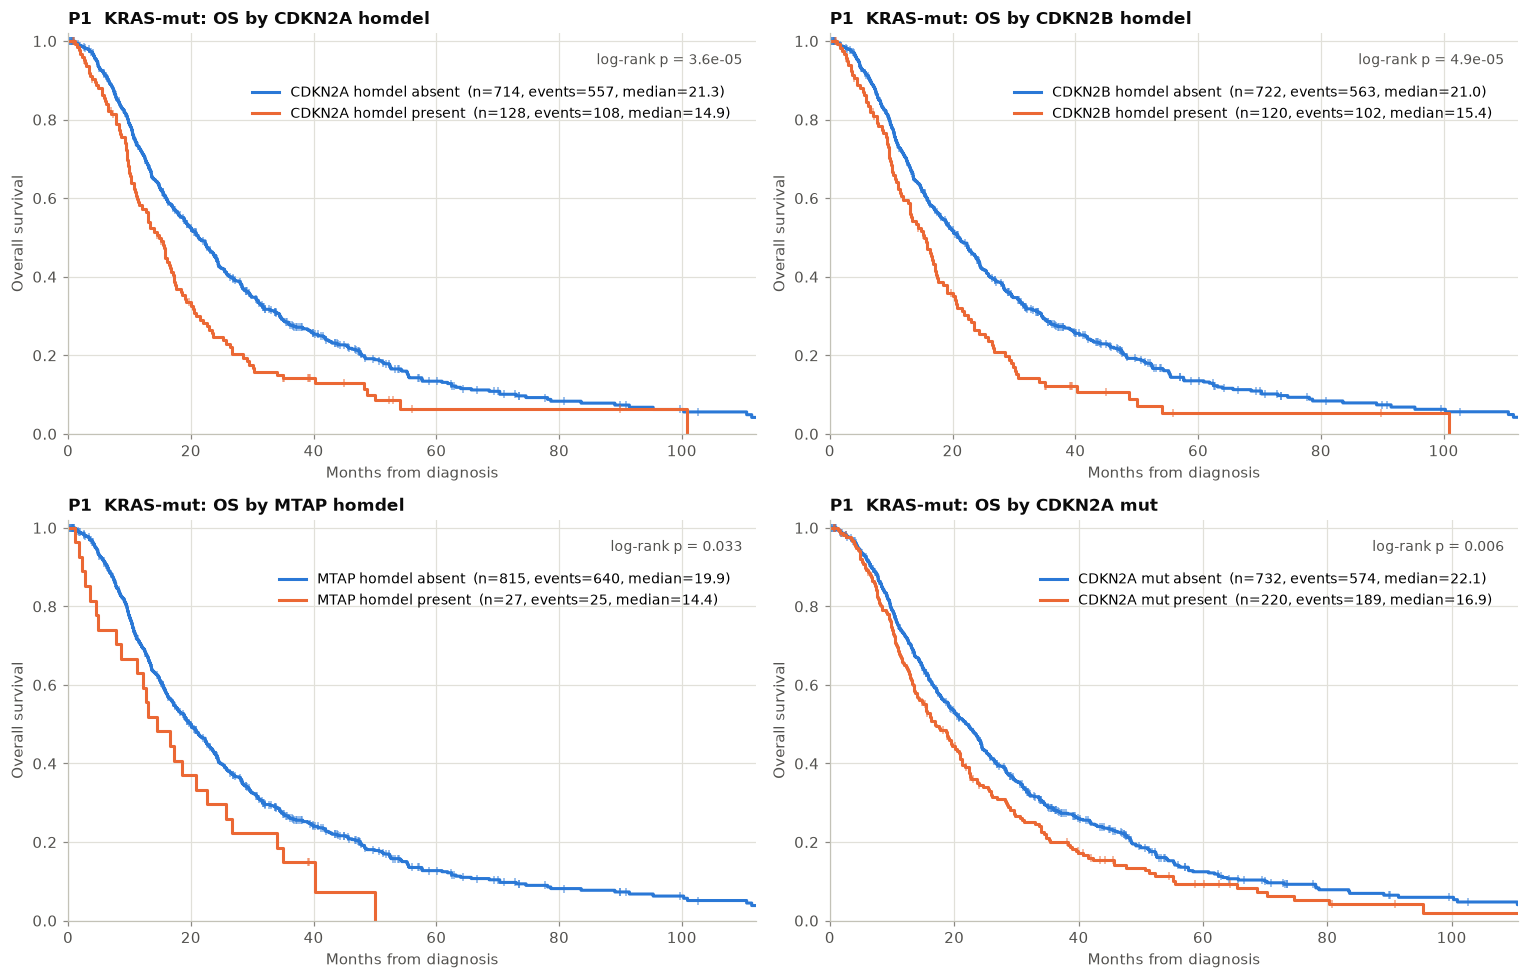

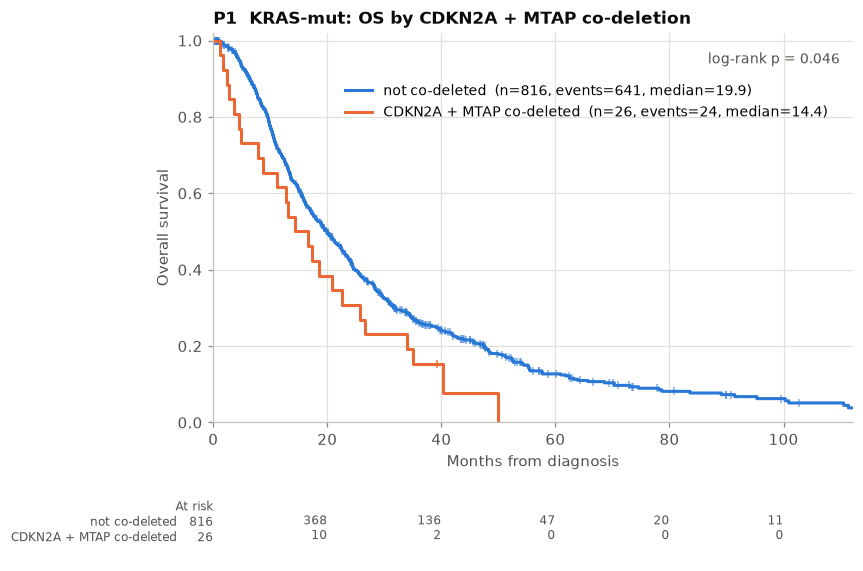

In [5]:
special = [("CDKN2A", "homdel"), ("CDKN2B", "homdel"), ("MTAP", "homdel"), ("CDKN2A", "mut"), ("TP53", "mut"), ("SMAD4", "mut"), ("SMAD4", "homdel")]
rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for (g, k), ax in zip(special[:4], axes.ravel()):
    d, t = cb.compare(S.loc[kras_ids], A.status(g, k), labels=(f"{g} {k} absent", f"{g} {k} present"), entry="entry")
    cb.km_plot(d, "group", order=[f"{g} {k} absent", f"{g} {k} present"], ax=ax, risk_table=False, title=f"P1  KRAS-mut: OS by {g} {k}", xlabel="Months from diagnosis")
    rows.append(t.assign(feature=f"{g} {k}"))
for g, k in special[4:]:
    d, t = cb.compare(S.loc[kras_ids], A.status(g, k), labels=(f"{g} {k} absent", f"{g} {k} present"), entry="entry")
    rows.append(t.assign(feature=f"{g} {k}"))
fig.tight_layout()
sp = pd.concat(rows).set_index(["feature", "group"])
cb.save(DS, "P1", table=sp.reset_index(), fig=fig, slug="special_genes")
display(sp)
# CDKN2A/B + MTAP co-deletion
codel = (A.status("CDKN2A", "homdel") & A.status("MTAP", "homdel")).rename("codel")
d, tcd = cb.compare(S.loc[kras_ids], codel, labels=("not co-deleted", "CDKN2A + MTAP co-deleted"), entry="entry", adjust=["stage_dx", "age_dx"])
ax, _ = cb.km_plot(d, "group", order=["not co-deleted", "CDKN2A + MTAP co-deleted"], title="P1  KRAS-mut: OS by CDKN2A + MTAP co-deletion", xlabel="Months from diagnosis")
cb.save(DS, "P1", table=tcd, fig=ax.figure, slug="cdkn2a_mtap_codeletion")
display(tcd)
hits = scr[scr.q_bh < 0.1]
cd = sp.loc[("CDKN2A homdel", "CDKN2A homdel present")]; mt = sp.loc[("MTAP homdel", "MTAP homdel present")]
cb.finding("P1", "signal" if len(hits) else "no signal at FDR<0.1",
           f"KRAS-mut n={len(kras_ids)}. FDR<0.1 co-alterations: " + (", ".join(f"{r.feature} (n={r.n_alt}) HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits.itertuples()) or "none") +
           f". CDKN2A homdel n={cd.n}: median {cd.median_months} vs {sp.loc[('CDKN2A homdel', 'CDKN2A homdel absent'), 'median_months']} mo, HR (LT) {cd.HR:.2f} (p={cb.fmt_p(cd.p_cox)}); "
           f"MTAP homdel n={mt.n}: HR {mt.HR:.2f} (p={cb.fmt_p(mt.p_cox)}); co-deletion adjusted HR {tcd.attrs['HR']:.2f} (p={cb.fmt_p(tcd.attrs['p_cox'])}).", F)

## Summary of findings

In [6]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,P1,signal,"KRAS-mut n=952. FDR<0.1 co-alterations: CDKN2A homdel (n=128) HR 1.47 q=0.0021, CDKN2B homdel (n=120) HR 1.53 q=0.0021, SMAD4 homdel (n=43) HR 1.66 q=0.0021, NTRK3 mut (n=15) HR 2.32 q=0.023, FLCN mut (n=10) HR 2.23 q=0.091, CDKN2A mut (n=220) HR 1.29 q=0.093, TP53 mut (n=737) HR 1.26 q=0.093, AKT2 amp (n=33) HR 1.53 q=0.093, CDK12 amp (n=11) HR 1.89 q=0.093. CDKN2A homdel n=128.0: median 14.9..."
